# Gradient Descent

## The Idea Behind Gradient Descent

Let's take a simple function that takes a vector and gives back one number: the sum of squares.

$$f(v) = v_1^2 + v_2^2 + \dots + v_n^2$$

Example: f([1, 2, 3]) = 1 + 4 + 9 = 14

It is smallest (= 0) when v = [0, 0, …, 0]. We already know that, but let's pretend we don't and let gradient descent find it.

In [2]:
import math
from functools import partial
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# Sum of the squared elements of v

# Plain Python
def sum_of_squares(v):
    return sum(v_i ** 2 for v_i in v)

print("Python:", sum_of_squares([1, 2, 3]))

# NumPy: no loop needed, works on the whole array at once
def sum_of_squares_np(v):
    return np.sum(v ** 2)

print("NumPy: ", sum_of_squares_np(np.array([1, 2, 3])))

Python: 14
NumPy:  14


### gradient:
The gradient is a vector that points in the direction where the function increases fastest (the "uphill" direction).

- To maximize a function $\to$ step with the gradient (go uphill)
- To minimize a function $\to$ step against the gradient (go downhill)

This is **gradient descent**

For sum of squares, the gradient is simply 2 × each element: gradient of [1, 2, 3] = [2, 4, 6].

Gradient descent on the simplest case, f(x) = $x^2$, starting at x = 8:

In [4]:
# Vector substract, multiplication and distance

def vector_subtract(v, w):
    return [v_i - w_i for v_i, w_i in zip(v, w)]

def scalar_multiply(c, v):
    return [c * v_i for v_i in v]

def distance(v, w):
    return math.sqrt(sum((v_i - w_i) ** 2 for v_i, w_i in zip(v, w)))

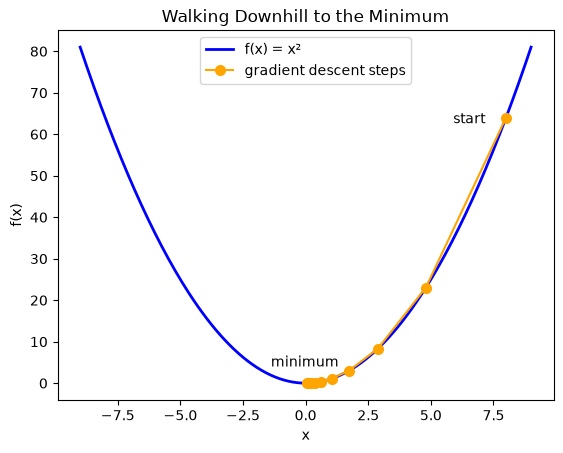

x after each step: [8.0, 4.8, 2.88, 1.728, 1.037, 0.622, 0.373, 0.224, 0.134, 0.081, 0.048]


In [5]:
f = lambda x: x ** 2
f_slope = lambda x: 2 * x              # derivative (slope) of x²

x = 8.0
path = [x]
for _ in range(10):
    x = x - 0.2 * f_slope(x)          # step AGAINST the slope
    path.append(x)

xs = np.linspace(-9, 9, 200)
plt.plot(xs, xs ** 2, color="blue", linewidth=2, label="f(x) = x²")
plt.plot(path, [f(p) for p in path], "o-", color="orange", markersize=7, label="gradient descent steps")
plt.annotate("start", (path[0], f(path[0])), textcoords="offset points", xytext=(-38, -4))
plt.annotate("minimum", (0, 0), textcoords="offset points", xytext=(-25, 12))
plt.title("Walking Downhill to the Minimum")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.legend()
plt.show()

print("x after each step:", [round(p, 3) for p in path])

## Estimating the Gradient

For a function of one variable, the derivative at x tells us how fast f(x) changes when x changes a tiny bit. It is the slope of the curve at that point.

We can estimate it using the difference quotient: move a tiny amount h and measure the change.

$$\text{slope} \approx \frac{f(x + h) - f(x)}{h} \quad \text{(for a very small } h\text{)}$$

For f(x) = $x^2$, we know the exact derivative is 2x. Let's check that our estimate matches.

x = 3 -> actual: 6 | estimate: 6.0
NumPy estimates for x = -2..2: [-4. -2.  0.  2.  4.]


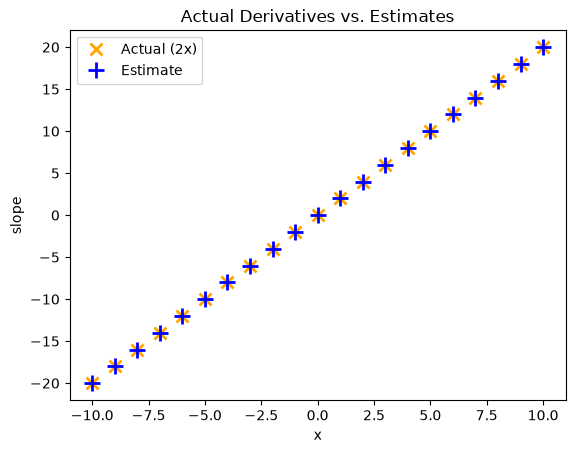

In [8]:
def square(x):
    return x ** 2

def derivative(x):
    return 2 * x

def difference_quotient(f, x, h):
    return (f(x + h) - f(x)) / h

derivative_estimate = partial(difference_quotient, square, h=0.00001)

# Plain Python
x_values = range(-10, 11)
actual = [derivative(x) for x in x_values]
estimate = [derivative_estimate(x) for x in x_values]  
print("x = 3 -> actual:", derivative(3), "| estimate:", round(derivative_estimate(3), 4))

# NumPy: the same formula works on a whole array in ONE line
x_arr = np.arange(-10, 11)
h = 0.00001
estimate_np = (square(x_arr + h) - square(x_arr)) / h
print("NumPy estimates for x = -2..2:", np.round(estimate_np[8:13], 4))

plt.plot(x_values, actual, "x", color='orange', markersize=9, markeredgewidth=2, label="Actual (2x)")
plt.plot(x_values, estimate, "+", color='blue', markersize=12, markeredgewidth=2, label="Estimate")
plt.title("Actual Derivatives vs. Estimates")
plt.xlabel("x")
plt.ylabel("slope")
plt.legend(loc="upper left")
plt.show()

In [10]:
# Plain Python
def partial_difference_quotient(f, v, i, h):
    """Estimate the i-th partial derivative of f at v"""
    w = [v_j + (h if j == i else 0)          # add h to ONLY the i-th element
         for j, v_j in enumerate(v)]
    return (f(w) - f(v)) / h

def estimate_gradient(f, v, h=0.00001):
    return [partial_difference_quotient(f, v, i, h) for i, _ in enumerate(v)]

print("Python estimate:", [round(g, 4) for g in estimate_gradient(sum_of_squares, [1, 2, 3])])

# NumPy: np.eye(n) gives n rows, each with a single 1, so we can nudge every element at once
def estimate_gradient_np(f, v, h=0.00001):
    v = np.asarray(v, dtype=float)
    nudges = np.eye(len(v)) * h                       # row i = add h to element i only
    return np.array([(f(v + nudge) - f(v)) / h for nudge in nudges])

print("NumPy estimate: ", np.round(estimate_gradient_np(sum_of_squares_np, [1, 2, 3]), 4))

Python estimate: [2.0, 4.0, 6.0]
NumPy estimate:  [2. 4. 6.]


## Using the Gradient

Now let's find the minimum of sum of squares for a 3-dimensional vector:
1. Start at a random point.
2. Calculate the gradient.
3. Take a small step against it.
4. Stop when the steps become tiny (we have "converged").

In [11]:
# Python progmming according to book

def step(v, direction, step_size):
    """Move step_size in the given direction from v"""
    return [v_i + step_size * direction_i for v_i, direction_i in zip(v, direction)]

def sum_of_squares_gradient(v):
    return [2 * v_i for v_i in v]

np.random.seed(0)
v = [np.random.randint(-10, 10) for _ in range(3)]       # random starting point
print("Start:", v)

tolerance = 0.0000001
iterations = 0
while True:
    gradient = sum_of_squares_gradient(v)    # 1. gradient at v
    next_v = step(v, gradient, -0.01)        # 2. step AGAINST the gradient (negative step)
    iterations += 1
    if distance(next_v, v) < tolerance:      # 3. stop if we barely moved
        break
    v = next_v                               # 4. otherwise keep going

print(f"End after {iterations} steps:", [round(v_i, 6) for v_i in v])

Start: [2, 5, -10]
End after 726 steps: [1e-06, 2e-06, -4e-06]


In [20]:
# In numpy v is an array, 
# so take a step is just one line of maths: v = v - step_size x gradient

v = np.random.randint(-10, 11, size=3).astype(float)       # random starting point
print("Start:", v)

step_size = 0.01
iterations = 0
while True:
    gradient = 2 * v                                  # gradient of sum of squares
    next_v = v - step_size * gradient                 # step against the gradient
    iterations += 1
    if np.linalg.norm(next_v - v) < tolerance:        # np.linalg.norm = distance
        break
    v = next_v

print(f"End after {iterations} steps:", np.round(v, 6))

Start: [ 6.  9. -5.]
End after 728 steps: [ 3.e-06  4.e-06 -2.e-06]


## Choosing the Right Step Size

Moving against the gradient is clear, but how big should each step be? This is more art than science.

| Step size | What happens | Hill example |
|---|---|---|
| Too small | Very slow, needs thousands of steps | Taking baby steps down the hill |
| Just right | Reaches the bottom quickly | Normal walking |
| Too big | Overshoots: jumps over the valley, zig-zags or even goes up | Leaping so far you land on the opposite hill |

Let's see this on f(x) = $x^2$, starting at x = 8:

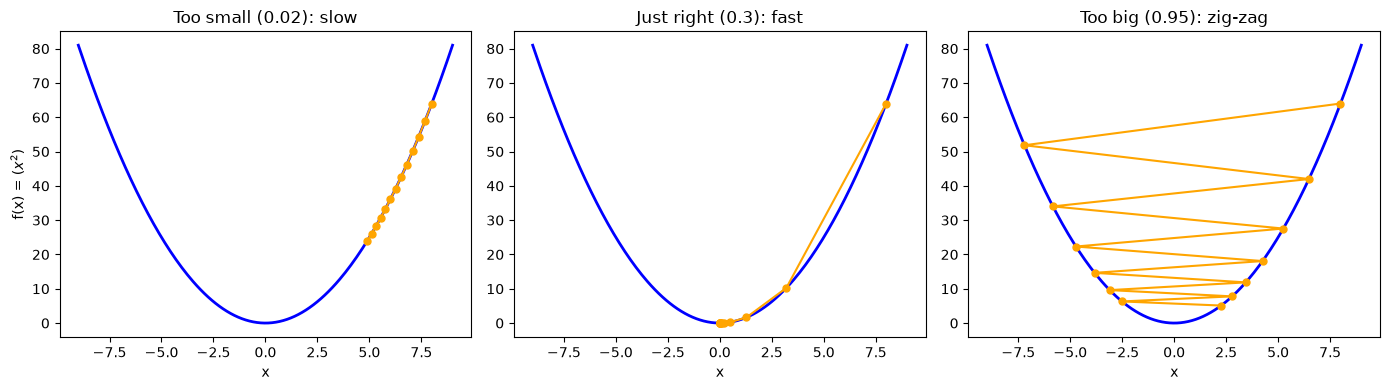

step size 0.02 -> x after 12 steps = 4.9017
step size 0.3  -> x after 12 steps = 0.0001
step size 0.95 -> x after 12 steps = 2.2594
step size 1.05 -> x after 12 steps = 25.1074


In [23]:
def descend(x0, step_size, n_steps=12):
    path = [x0]
    for _ in range(n_steps):
        path.append(path[-1] - step_size * 2 * path[-1])     # x <- x − step × slope
    return np.array(path)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (lr, label) in zip(axes, [(0.02, "Too small (0.02): slow"),
                                  (0.3, "Just right (0.3): fast"),
                                  (0.95, "Too big (0.95): zig-zag")]):
    path = descend(8.0, lr)
    ax.plot(xs, xs ** 2, color='blue', linewidth=2)
    ax.plot(path, path ** 2, "o-", color='orange', markersize=5)
    ax.set_title(label, fontsize=12)
    ax.set_xlabel("x")
axes[0].set_ylabel(r"f(x) = ($x^2$)")
plt.tight_layout()
plt.show()

for lr in [0.02, 0.3, 0.95, 1.05]:
    print(f"step size {lr:<4} -> x after 12 steps = {descend(8.0, lr)[-1]:.4f}")

In [29]:
# When we try big step sizes, the function might crash (example a number too large). 
# The book wraps the function so that an error simply returns infinity, 
# which can never be chosen as the minimum.

def safe(f):
    """Return a new function that is the same as f, but returns infinity if f gives an error"""
    def safe_f(*args, **kwargs):
        try:
            return f(*args, **kwargs)
        except Exception:
            return float("inf")      # "infinity" in Python
    return safe_f

def risky(x):
    return math.exp(x)               # math.exp(10000) is too big -> OverflowError

safe_risky = safe(risky)
print("safe_risky(2)    =", safe_risky(2))
print("safe_risky(10000) =", safe_risky(10000))

safe_risky(2)    = 7.38905609893065
safe_risky(10000) = inf


## Putting It All Together:

Now a real use of gradient descent. A teacher collected data from 8 students:

| Hours studied | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
|---|---|---|---|---|---|---|---|---|
| **Marks** | 38 | 43 | 52 | 58 | 64 | 73 | 79 | 85 |

We want the best straight line: marks = $\theta_0$ + $\theta_1$ × hours
- $\theta_0$ = the starting marks (intercept)
- $\theta_1$ = extra marks for each extra hour (slope)

"Best" = the line with the smallest total squared error between the predicted and actual marks. So:
- target function = total squared error (what we minimise)
- theta = [$\theta_0$, $\theta_1$] (what we change)

In [30]:
hours = [1, 2, 3, 4, 5, 6, 7, 8]
marks = [38, 43, 52, 58, 64, 73, 79, 85]

# Plain Python: error and gradient for the whole data set
def predict(theta, x_i):
    return theta[0] + theta[1] * x_i

def total_squared_error(theta):
    return sum((y_i - predict(theta, x_i)) ** 2 for x_i, y_i in zip(hours, marks))

def total_squared_error_gradient(theta):
    """Partial derivatives of the total squared error with respect to θ₀ and θ₁"""
    errors = [y_i - predict(theta, x_i) for x_i, y_i in zip(hours, marks)]
    d_theta0 = sum(-2 * e for e in errors)
    d_theta1 = sum(-2 * e * x_i for e, x_i in zip(errors, hours))
    return [d_theta0, d_theta1]

print("Error of a bad guess θ = [0, 0]:  ", total_squared_error([0, 0]))
print("Error of a better guess θ = [30, 7]:", total_squared_error([30, 7]))

Error of a bad guess θ = [0, 0]:   32252
Error of a better guess θ = [30, 7]: 6


In [33]:
# At each step it tries many step sizes [100, 10, 1, 0.1, …] and 
# keeps the one that gives the smallest error. 
# It stops when the error stops improving.
# It is called batch because every step uses the whole data set.


def minimize_batch(target_fn, gradient_fn, theta_0, tolerance=0.000001):
    """Use gradient descent to find the theta that minimises target_fn"""
    step_sizes = [100, 10, 1, 0.1, 0.01, 0.001, 0.0001, 0.00001]

    theta = theta_0                         # start here
    target_fn = safe(target_fn)             # safe version of the target
    value = target_fn(theta)                # the value we are minimising

    while True:
        gradient = gradient_fn(theta)
        next_thetas = [step(theta, gradient, -step_size) for step_size in step_sizes]

        # choose the step that gives the smallest error
        next_theta = min(next_thetas, key=target_fn)
        next_value = target_fn(next_theta)

        # stop if we are hardly improving any more ("converging")
        if abs(value - next_value) < tolerance:
            return theta
        theta, value = next_theta, next_value

theta_batch = minimize_batch(total_squared_error, total_squared_error_gradient, [0, 0])
print(f"batch: marks = {theta_batch[0]:.2f} + {theta_batch[1]:.2f} × hours")

batch: marks = 30.53 + 6.88 × hours


In [38]:
# Maximising instead of minimising
# To maximise a function, just minimise its negative. 
# The highest point of a hill is the lowest point of the hill turned upside down

def negate(f):
    """Return a function that gives -f(x)"""
    return lambda *args, **kwargs: -f(*args, **kwargs)

def negate_all(f):
    """The same, when f returns a list of numbers"""
    return lambda *args, **kwargs: [-y for y in f(*args, **kwargs)]

def maximize_batch(target_fn, gradient_fn, theta_0, tolerance=0.000001):
    return minimize_batch(negate(target_fn), negate_all(gradient_fn), theta_0, tolerance)

# Example: a shop's profit (thousand rupees) for price p is 10 − (p − 3)², so the best price is p = 3
profit = lambda theta: 10 - (theta[0] - 3) ** 2
profit_gradient = lambda theta: [-2 * (theta[0] - 3)]

best = maximize_batch(profit, profit_gradient, [0])
print(f"Best price ≈ {best[0]:.3f}, maximum profit ≈ {profit(best):.3f}")

Best price ≈ 2.998, maximum profit ≈ 10.000


## Stochastic Gradient Descent (SGD)

Batch gradient descent looks at all the data before taking one step. With lakhs of rows, every step becomes very slow.

Stochastic Gradient Descent (SGD) takes a step after looking at just one data point:
1. Shuffle the data into a random order (stochastic means "random").
2. For each data point, calculate its gradient and take a small step.
3. Repeat over the data many times. Each full pass is called an epoch.

| | Batch GD | Stochastic GD |
|---|---|---|
| Data used per step | All data points | One data point |
| Speed per step | Slow | Very fast |
| Path to the minimum | Smooth | Noisy / zig-zag, but gets there |
| Good for | Small data | Big data |

Example: A teacher improving her teaching method.
- Batch: waits until all 60 students submit feedback, then makes one change.
- SGD: makes a small change after each student's feedback.

In [48]:
def squared_error(x_i, y_i, theta):
    return (y_i - predict(theta, x_i)) ** 2

def squared_error_gradient(x_i, y_i, theta):
    error = y_i - predict(theta, x_i)
    return [-2 * error, -2 * error * x_i]

def in_random_order(data):
    """Generator that returns the elements of data in random order"""
    indexes = [i for i, _ in enumerate(data)]
    np.random.shuffle(indexes)
    for i in indexes:
        yield data[i]

def minimize_stochastic(target_fn, gradient_fn, x, y, theta_0, alpha_0=0.01):
    data = list(zip(x, y))            # zip(x, y) without list()
    theta = theta_0                   # starting guess
    alpha = alpha_0                   # starting step size
    min_theta, min_value = None, float("inf")
    iterations_with_no_improvement = 0

    # stop after 100 passes in a row with no improvement
    while iterations_with_no_improvement < 100:
        value = sum(target_fn(x_i, y_i, theta) for x_i, y_i in data)

        if value < min_value:
            # new best: remember it and reset the step size
            min_theta, min_value = theta, value
            iterations_with_no_improvement = 0
            alpha = alpha_0
        else:
            # not improving: shrink the step size
            iterations_with_no_improvement += 1
            alpha *= 0.9

        # take one gradient step for EACH data point
        for x_i, y_i in in_random_order(data):
            gradient_i = gradient_fn(x_i, y_i, theta)
            theta = vector_subtract(theta, scalar_multiply(alpha, gradient_i))

    return min_theta

np.random.seed(0)
theta_sgd = minimize_stochastic(squared_error, squared_error_gradient, hours, marks, [0, 0], 0.01)
print(f"Plain Python (SGD): marks = {theta_sgd[0]:.2f} + {theta_sgd[1]:.2f} × hours")

Plain Python (SGD): marks = 30.56 + 6.88 × hours
